# Including weather data in an LSTM
This notebook contains an attempt to include weather data in an LSTM predicting electricity prices. Unfortunately, it does not outperform the trivial model and is therefore an unsuccessful attempt

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import csv
from datetime import datetime, timezone, timedelta
import numpy as np
import matplotlib.pyplot as plt

# Data merging
We have to combine the two datasets that are the price data and the weather data

In [2]:
infile_price  = open("price_data.csv", "r")
reader_price = csv.reader(infile_price)
infile_weather = open("weather_data.csv", "r")
reader_weather = csv.reader(infile_weather)

price_list= []
weather_list = []
for line in reader_price:
    price_list.append([[int(line[0]),float(line[1])]])
for line in reader_weather:
    if len(line)==7:
        weather_list.append([[int(line[0])]+[ float(item) for item in line[1:] ]])
infile_price.close()
infile_weather.close()

We will check the last timestamp for weather and price data. We always need to make sure, weather data is more recent than price data

In [3]:
print(datetime.utcfromtimestamp(price_list[-1][0][0]/1000))

2026-08-30 21:00:00


In [4]:
print(datetime.utcfromtimestamp(weather_list[-1][0][0]/1000))

2026-09-01 23:00:00


Instead of just filtering for the times to correspond to each other, I will include the dates from which on both weather and price data are available. In order to make a combined tensor of price and weather I will then use the closest time stammp weather data after that time

In [5]:
min_time = max(weather_list[0][0][0], price_list[0][0][0])
max_time = min(weather_list[-1][0][0], price_list[-1][0][0])

#Delete anything that happened before min_time and anything that happened after max_time
for index, line in enumerate(price_list):
    if line[0][0]<min_time or line[0][0]>max_time:
        price_list.pop(index)
for index, line in enumerate(weather_list):
    if line[0][0]<min_time or line[0][0]>max_time:
        weather_list.pop(index)

# Now add the weather data into the price list, taking the time stamp that comes directly after the price timestamp
last_weather_index= 0 
for i,line in enumerate(price_list):
    if len(line[0])>2:
        raise ValueError("The lists have already been merged")
    if last_weather_index == len(weather_list)-1:
        print('WARNING: Weather data may not go as far as electricity price data')
    if i%1000 == 0:
        print("progress: "+str(i)+"/"+str(len(price_list)//1000*1000),end="\r")
    timestamp = line[0][0]
    # The search will start from the place in the list where the last time stamp was found (last_weather_index) and find the next timestamp over our timestamp
    for j,weather_line in enumerate(weather_list[last_weather_index:]): 
        if weather_line[0][0] >= timestamp:
            break
    last_weather_index = last_weather_index + j
    for value in weather_line[0][1:]:
        line[0].append(value)

progress: 40000/40000

Now that we have the weather data in the price list, let's expand the timestamp as year, month, day, hour

In [6]:
for line in price_list:
    timestamp = line[0][0]
    line[0].pop(0)
    time_object = datetime.utcfromtimestamp(timestamp/1000)
    year = int(time_object.year)
    line[0].insert(0,year)
    month = int(time_object.month)
    line[0].insert(1,month)
    day = int(time_object.day)
    line[0].insert(2,day)
    hour = int(time_object.hour)
    line[0].insert(3,hour)
price_list

[[[2022, 1, 2, 23, 0.31, 0.0, 0.0, 0.0, 39.28456, 45.218353, 27.438046]],
 [[2022, 1, 3, 0, -0.01, 0.0, 0.0, 0.0, 44.477123, 41.699436, 21.892027]],
 [[2022, 1, 3, 1, -0.07, 0.0, 0.0, 0.0, 43.96129, 40.076588, 21.096123]],
 [[2022, 1, 3, 2, -1.05, 0.0, 0.0, 0.0, 43.77369, 38.941616, 28.291512]],
 [[2022, 1, 3, 3, -1.0, 0.0, 0.0, 0.0, 41.638786, 39.658867, 34.627434]],
 [[2022, 1, 3, 4, 0.32, 0.0, 0.0, 0.0, 38.48129, 40.52839, 38.479603]],
 [[2022, 1, 3, 5, 37.55, 0.0, 0.0, 0.0, 37.834267, 39.39986, 40.257275]],
 [[2022, 1, 3, 6, 88.76, 0.0, 0.0, 0.0, 39.081146, 38.48129, 42.242897]],
 [[2022, 1, 3, 7, 122.93, 0.0, 0.0, 0.0, 39.047966, 36.30471, 39.619625]],
 [[2022, 1, 3, 8, 110.17, 10.0, 6.0, 1.0, 39.8447, 35.747112, 41.514103]],
 [[2022, 1, 3, 9, 93.38, 57.0, 49.0, 16.0, 37.372437, 34.65175, 41.23532]],
 [[2022, 1, 3, 10, 90.73, 112.0, 80.0, 67.0, 33.636406, 34.06521, 43.063282]],
 [[2022, 1, 3, 11, 82.37, 92.0, 135.0, 68.0, 32.682762, 38.183765, 41.742928]],
 [[2022, 1, 3, 12, 80.9,

As we can see, the price_list contains
[year, month, day, hour, price, sunlight, sunlight, sunlight, wind, wind ,wind]

In [7]:
price_list[0],price_list[-1]

([[2022, 1, 2, 23, 0.31, 0.0, 0.0, 0.0, 39.28456, 45.218353, 27.438046]],
 [[2026, 8, 30, 21, 168.79, 0.0, 0.0, 0.0, 19.800817, 18.745079, 18.201374]])

In [8]:
price_data_tensor = torch.tensor(price_list)
only_the_prices = price_data_tensor[:,:,4:5]
only_the_weather = torch.cat((price_data_tensor[:,:,:4],price_data_tensor[:,:,5:]),dim=2)

# Shifting the weather data by a day
The idea here is that the weather data the model gets together with today's prices is the weather data for tomorrow. The reason for this is that the model is supposed to use today's prices and tomorrow's weather in order to obtain tomorrow's prices

In [9]:
weather_data = price_data_tensor[:,:,5:]
weather_data_shifted = torch.roll(weather_data,24,0)
price_data_shifted = torch.cat((price_data_tensor[:,:,:5],weather_data_shifted),dim=-1)

In [10]:
#checking that thee shifting worked
for i in range(len(price_data_shifted)-24):
    if not price_data_shifted[i+24,0,-1]==price_data_tensor[i,0,-1]:
        print("Problem")

Remove the last 24 entries so there is no overflow issue

In [11]:
price_data_shifted = price_data_shifted[:-24]
price_data_shifted.shape

torch.Size([40799, 1, 11])

In [12]:
price_data_shifted[0]

tensor([[2.0220e+03, 1.0000e+00, 2.0000e+00, 2.3000e+01, 3.1000e-01, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 2.3356e+01, 3.3735e+01, 2.6836e+01]])

# Putting the data day-wise
I need to put the data together per day

In [13]:
day_number = len(price_data_shifted)//24
day_number

1699

In [14]:
def make_daywise(the_tensor):
    the_elements = len(the_tensor[0,0])
    zahl_tage = int(len(the_tensor)/(24))
    if not zahl_tage*24 == len(the_tensor):
        print("Warning, the number of hours is not a multiple of 24")
        the_tensor = the_tensor[:zahl_tage*24]
    b = the_tensor.transpose(0,2)
    c = b.reshape(the_elements,zahl_tage,24)
    d = c.transpose(0,1)
    e = d.reshape(zahl_tage,1,the_elements*24)
    return e

In [15]:
#let's test the make daywise function
test_list = []
for i in range(24):
    test_list.append([[2022,1,1,i,-10+0.1*i,20,30,40]])
test_tensor = torch.tensor(test_list)
make_daywise(test_tensor)

tensor([[[ 2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1

In [16]:
price_data_shifted[0]

tensor([[2.0220e+03, 1.0000e+00, 2.0000e+00, 2.3000e+01, 3.1000e-01, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 2.3356e+01, 3.3735e+01, 2.6836e+01]])

In [17]:
price_data_shifted.shape

torch.Size([40799, 1, 11])

In [18]:
price_data_daywise = make_daywise(price_data_shifted)
price_data_daywise[0], price_data_daywise.shape

Warning, the number of hours is not a multiple of 24


(tensor([[ 2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  2.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3

So far the tensor starts with the year 24 times, the month 24 times, the day 24 times and the times we will cut the redundant part away. We take the 3rd entry for the date, because during summer time midnight is UTC 22:00 and thus the previous day. Therefore taking the third date of the day gives the correct date

In [19]:
def remove_unnecessary_date(X):
    return torch.cat((X[:,:,2:3],X[:,:,2+24:3+24],X[:,:,2+2*24:3+2*24],X[:,:,4*24:]),dim=-1)
price_data_daywise_better = remove_unnecessary_date(price_data_daywise)

In [20]:
price_data_daywise_better[0]

tensor([[ 2.0220e+03,  1.0000e+00,  3.0000e+00,  3.1000e-01, -1.0000e-02,
         -7.0000e-02, -1.0500e+00, -1.0000e+00,  3.2000e-01,  3.7550e+01,
          8.8760e+01,  1.2293e+02,  1.1017e+02,  9.3380e+01,  9.0730e+01,
          8.2370e+01,  8.0900e+01,  8.0990e+01,  9.8050e+01,  1.2351e+02,
          1.4849e+02,  1.3800e+02,  1.1764e+02,  1.1771e+02,  9.5950e+01,
          1.0568e+02,  9.5260e+01,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  3.0000e+00,
          7.1000e+01,  2.4500e+02,  4.0900e+02,  5.5500e+02,  6.5200e+02,
          6.9800e+02,  7.6400e+02,  6.8400e+02,  6.2700e+02,  4.7200e+02,
          3.2400e+02,  1.9300e+02,  5.0000e+01,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  5.0000e+00,  6.3000e+01,
          1.5800e+02,  2.1600e+02,  4.5600e+02,  6.0400e+02,  7.0400e+02,
          4.4600e+02,  5.6000e+02,  4.

# Normalizing the data
Right now the data isn't in between 0 and 1, we normalize all of its components in order to feed it into the neural network. Built in here is the assumption that it will never be higher or lower than the highest/lowest datapoint in the past

In [21]:
with torch.no_grad():
    minimal_values = price_data_daywise_better.min(dim=0).values
    minimum_price = float(minimal_values[0,3:3+24].min())
    maximal_values = price_data_daywise_better.max(dim=0).values+0.000001 #so we never divide by zero there is a tiny offset here
    maximum_price = float(maximal_values[0,3:3+24].max())
    #thinking if I want to make all price fields scaled by the same amount, doesn't actually improve anything though
    #for i in range(24):
    #    minimal_values[0,3+i] = minimum_price
    #    maximal_values[0,3+i] = maximum_price
    difference = maximal_values-minimal_values 
    price_data_normalized = (price_data_daywise_better-minimal_values.unsqueeze(1)) / difference.unsqueeze(1)
price_data_normalized.shape , price_data_daywise_better.shape

(torch.Size([1699, 1, 171]), torch.Size([1699, 1, 171]))

In [22]:
price_data_normalized.max(dim=0).values

tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 0.0000, 0.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0

In [23]:
def de_normalize_data(the_tensor , minimum= minimal_values , maximum= maximal_values):
    difference = maximum - minimum
    return the_tensor*difference.unsqueeze(1) + minimum.unsqueeze(1)

In [24]:
cutting_index = int(len(price_data_normalized)/3*2)
training_data= price_data_normalized[:cutting_index]
training_target = price_data_normalized[1:cutting_index+1,:,3:3+24]
evaluation_data = price_data_normalized[cutting_index:-1]
evaluation_target = price_data_normalized[cutting_index+1:,:,3:3+24]

# Setting up the learning model
This model is going to input the history of price and weather together with the future weather. The history will be put into a LSTM. The LSTM hidden state will go through a linear and a nonlinear layer. Then, the output of this LSTM section will be put together with the last day's price distribution and the weather for the to be predicted day using a linear layer.

In [25]:
class LSTM_predictor(nn.Module):
    def __init__(self, source_dim, hidden_dim, target_size):
        super(LSTM_predictor, self).__init__()
        self.hidden_dim = hidden_dim
        self.lstm = nn.LSTM(source_dim, hidden_dim)
        self.hidden2predict = nn.Linear(hidden_dim+24, target_size)
    def forward(self, input):
        lstm_out , _ = self.lstm(input)
        prediction_in = torch.cat((lstm_out, input[:,:,3:3+24]), dim=-1)
        prediction = self.hidden2predict(prediction_in)
        return prediction

In [26]:
SLIDING_WINDOW_LENGTH = 14
HIDDEN_DIMENSION = 20
data_dimensionality = len(training_data[0,0])

model = LSTM_predictor(data_dimensionality, HIDDEN_DIMENSION, 24)
loss_function = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

## First Training
Below the model gets trained. We will later train again with different hyperparameters to obtain better results

In [27]:
EPOCH_NUMBER = 20
for epoch in range(EPOCH_NUMBER): 
    print("Epoch: "+str(epoch+1)+"/"+str(EPOCH_NUMBER))
    for i in range(len(training_data)-SLIDING_WINDOW_LENGTH):
        training_line = training_data[i:i+SLIDING_WINDOW_LENGTH]
        result_line = training_target[i:i+SLIDING_WINDOW_LENGTH]
        model.zero_grad()
        prediction  = model(training_line)
        loss = loss_function(prediction, result_line)
        loss.backward()
        optimizer.step()
print("Finished")

Epoch: 1/20
Epoch: 2/20
Epoch: 3/20
Epoch: 4/20
Epoch: 5/20
Epoch: 6/20
Epoch: 7/20
Epoch: 8/20
Epoch: 9/20
Epoch: 10/20
Epoch: 11/20
Epoch: 12/20
Epoch: 13/20
Epoch: 14/20
Epoch: 15/20
Epoch: 16/20
Epoch: 17/20
Epoch: 18/20
Epoch: 19/20
Epoch: 20/20
Finished


# Evaluating on separate data

In [28]:
def de_normalize_prediction(result_tensor,minimums =minimal_values[:,3:3+24] , maximums = maximal_values[:,3:3+24] ):
    return de_normalize_data(result_tensor, minimum = minimums, maximum=maximums)

In [29]:
import math
SLIDING_WINDOW_EVAL = 4

def evaluate_model_on_dataset(eval_dataset,eval_target,the_model):
    mean_off = 0
    for i in range(len(eval_dataset)-SLIDING_WINDOW_EVAL):
        data = eval_dataset[i:i+SLIDING_WINDOW_EVAL]
        prediction = the_model(data)
        target = de_normalize_prediction(eval_target[i:i+SLIDING_WINDOW_EVAL])
        prediction_de_normalized = de_normalize_prediction(prediction)
        how_off = prediction_de_normalized - target
        mean_off_today = 0
        for i in range(24):
            mean_off_today += abs(float(how_off[0][0][i]))/24
        mean_off += mean_off_today / (len(eval_dataset)-SLIDING_WINDOW_EVAL)
    return mean_off
    
off = evaluate_model_on_dataset(evaluation_data,evaluation_target,model)
print(off)

30.565593864322388


/tmp/ipykernel_21298/647309216.py:14: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:822.)
  mean_off_today += abs(float(how_off[0][0][i]))/24


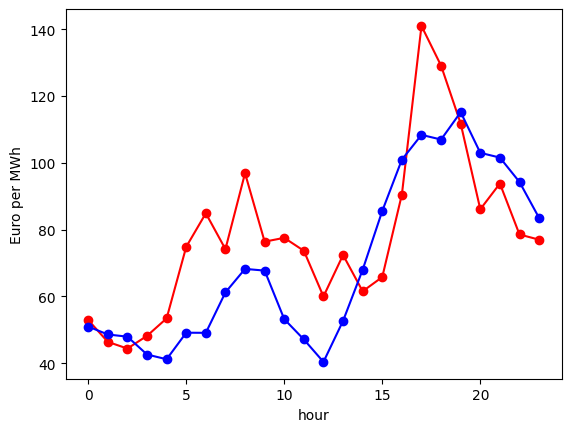

In [30]:
import matplotlib.pyplot as plt
def draw_model_vs_target(eval_dataset,eval_target,the_model,index=0,compare_model= None):
    data = eval_dataset[index:index+SLIDING_WINDOW_EVAL]
    prediction = the_model(data)
    actual_value = list(de_normalize_prediction(eval_target[index:index+SLIDING_WINDOW_EVAL])[-1,0,:])
    prediction_de_normalized = de_normalize_prediction(prediction)[-1,0,:].detach().numpy()
    if compare_model != None:
        compare_prediction = compare_model(data)
        compare_de_normalized = de_normalize_prediction(compare_prediction)[-1,0,:].detach().numpy()
        plt.plot(compare_de_normalized,marker='o',color='green')
    plt.plot(prediction_de_normalized,marker='o',color='red')
    plt.plot(actual_value,marker='o',color='blue')
    plt.ylabel("Euro per MWh")
    plt.xlabel("hour")
    plt.show()
draw_model_vs_target(evaluation_data,evaluation_target,model,10)

We will compare this to the trivial model, which assumes that today's electricity prices will be exactly like yesterday's

In [31]:
def trivial_model(input):
    '''The model that predicts tomorrows price to be the same as today's price'''
    return input[:,:,3:3+24]

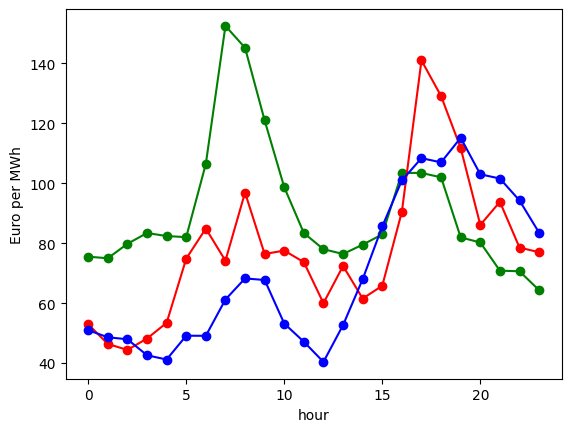

In [32]:
draw_model_vs_target(evaluation_data,evaluation_target,model,10,trivial_model)

In [33]:
trivial_off = evaluate_model_on_dataset(evaluation_data,evaluation_target,trivial_model)
print("The trivial model's mean absolute error is",trivial_off)

The trivial model's mean absolute error is 26.602305794225316


# Improve the model
So far the model is quite bad, let's try different ways to improve it. First of all, currently the error function is looking at all days, not just the final day. This doesn't fully make sense. We first change it in the evaluation function, then in the model. We also will play with some of the hyperparameters.

In [48]:
def evaluate_model_on_dataset(eval_dataset,eval_target,the_model):
    mean_off = 0
    for i in range(len(eval_dataset)-SLIDING_WINDOW_EVAL):
        data = eval_dataset[i:i+SLIDING_WINDOW_EVAL]
        prediction = the_model(data)
        target = de_normalize_prediction(eval_target[i:i+SLIDING_WINDOW_EVAL])[-1:]
        prediction_de_normalized = de_normalize_prediction(prediction)[-1:]
        how_off = prediction_de_normalized - target
        mean_off_today = 0
        for i in range(24):
            mean_off_today += abs(float(how_off[0][0][i]))/24
        mean_off += mean_off_today / (len(eval_dataset)-SLIDING_WINDOW_EVAL)
    return mean_off

In [49]:
class LSTM_predictor(nn.Module):
    def __init__(self, source_dim, hidden_dim, target_size):
        super(LSTM_predictor, self).__init__()
        self.hidden_dim = hidden_dim
        self.lstm = nn.LSTM(source_dim, hidden_dim)
        self.hidden2predict = nn.Linear(hidden_dim+24, target_size)
    def forward(self, input):
        lstm_out , _ = self.lstm(input)
        prediction_in = torch.cat((input[:,:,3:3+24],lstm_out), dim=-1)
        prediction = self.hidden2predict(prediction_in)
        return prediction

In [64]:
SLIDING_WINDOW_LENGTH = 14
SLIDING_WINDOW_EVAL = SLIDING_WINDOW_LENGTH
HIDDEN_DIMENSION = 100
data_dimensionality = len(training_data[0,0])

model = LSTM_predictor(data_dimensionality, HIDDEN_DIMENSION, 24)
loss_function = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.05)
error_list = [] # list the keeps track of the mean absolute error of different training steps

In [65]:
EPOCH_NUMBER = 200
for epoch in range(EPOCH_NUMBER): 
    if not epoch%5:
        print("Epoch: "+str(epoch+1)+"/"+str(EPOCH_NUMBER))
    for i in range(len(training_data)-SLIDING_WINDOW_LENGTH):
        training_line = training_data[i:i+SLIDING_WINDOW_LENGTH]
        result_line = training_target[i:i+SLIDING_WINDOW_LENGTH]
        model.zero_grad()
        prediction  = model(training_line)[-1]
        loss = loss_function(prediction, result_line[-1])
        loss.backward()
        optimizer.step()
    mean_error = evaluate_model_on_dataset(evaluation_data,evaluation_target,model)
    if not epoch%5:
        print("Mean absolute error:"+str(float(mean_error)))
    error_list.append(mean_error)
    if error_list[-1] > error_list[int(len(error_list)/2)]+0.3 or error_list[-1] > error_list[int(999*len(error_list)/1000)]+0.3:
        print("Training makes the fit significantly worse, aborting")
        break
print("Finished")

Epoch: 1/200
Mean absolute error:44.11875073964467
Epoch: 6/200
Mean absolute error:32.243707832938796
Epoch: 11/200
Mean absolute error:29.886474993961762
Epoch: 16/200
Mean absolute error:28.861962641026995
Epoch: 21/200
Mean absolute error:28.27724040166479
Epoch: 26/200
Mean absolute error:27.923556973068877
Epoch: 31/200
Mean absolute error:27.70870935866513
Epoch: 36/200
Mean absolute error:27.583733622398626
Epoch: 41/200
Mean absolute error:27.519308962251834
Epoch: 46/200
Mean absolute error:27.49550353210183
Epoch: 51/200
Mean absolute error:27.501591635786948
Epoch: 56/200
Mean absolute error:27.529427892488
Epoch: 61/200
Mean absolute error:27.573921954142275
Epoch: 66/200
Mean absolute error:27.633057386618898
Epoch: 71/200
Mean absolute error:27.706705013910938
Epoch: 76/200
Mean absolute error:27.791786502524868
Training makes the fit significantly worse, aborting
Finished


trivial error: 26.63760720313961


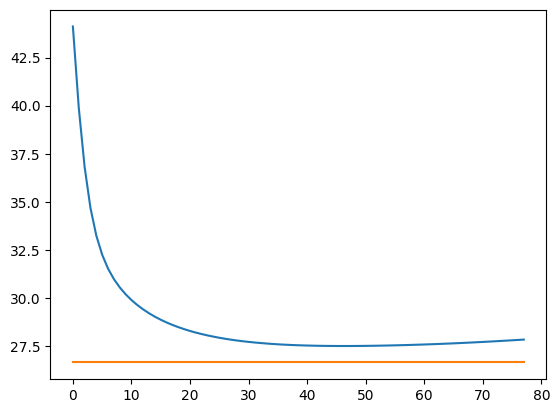

In [66]:
trivial_model_error= evaluate_model_on_dataset(evaluation_data,evaluation_target,trivial_model)
print("trivial error:",trivial_model_error)
plt.plot(error_list)
plt.plot(trivial_model_error*np.ones(len(error_list)))
plt.show()

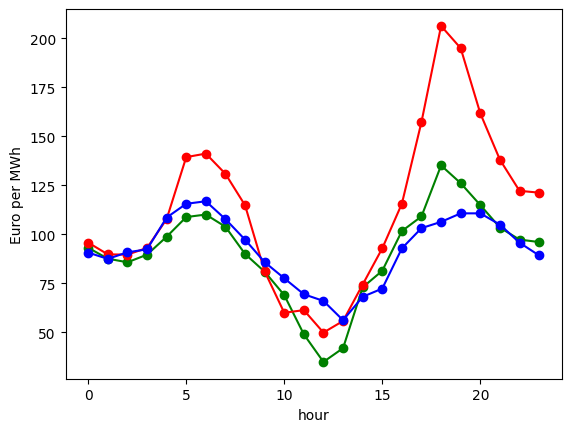

In [57]:
draw_model_vs_target(evaluation_data,evaluation_target,model,180,trivial_model)

This is still really bad

# Try reducing the size of the data by averaging weather data

In [58]:
date_and_prices_only = price_data_daywise_better[:,:,:3+24]
average_sunlight = price_data_daywise_better[:,:,3+24:3+4*24].mean(dim=-1)
average_wind = price_data_daywise_better[:,:,3+4*24:3+7*24].mean(dim=-1)
price_data_weather_reduced = torch.cat((date_and_prices_only,average_sunlight.unsqueeze(-1),average_wind.unsqueeze(-1)),dim=-1)
price_data_weather_reduced.shape

torch.Size([1699, 1, 29])

In [59]:
with torch.no_grad():
    minimal_reduced = price_data_weather_reduced.min(dim=0).values
    maximal_reduced = price_data_weather_reduced.max(dim=0).values+0.000001 #so we never divide by zero there is a tiny offset here
    #thinking if I want to make all price fields scaled by the same amount, doesn't actually improve anything though
    #for i in range(24):
    #    minimal_values[0,3+i] = minimum_price
    #    maximal_values[0,3+i] = maximum_price
    difference = maximal_reduced-minimal_reduced 
    price_data_reduced_normalized = (price_data_weather_reduced-minimal_reduced.unsqueeze(1)) / difference.unsqueeze(1)
price_data_reduced_normalized.shape , price_data_weather_reduced.shape

(torch.Size([1699, 1, 29]), torch.Size([1699, 1, 29]))

In [60]:
cutting_index = int(len(price_data_normalized)/3*2)
training_data_reduced= price_data_reduced_normalized[:cutting_index]
training_target_reduced = price_data_reduced_normalized[1:cutting_index+1,:,3:3+24]
evaluation_data_reduced = price_data_reduced_normalized[cutting_index:-1]
evaluation_target_reduced = price_data_reduced_normalized[cutting_index+1:,:,3:3+24]

In [61]:
SLIDING_WINDOW_LENGTH = 14
SLIDING_WINDOW_EVAL = SLIDING_WINDOW_LENGTH
HIDDEN_DIMENSION = 100
data_dimensionality = len(training_data_reduced[0,0])

model_reduced = LSTM_predictor(data_dimensionality, HIDDEN_DIMENSION, 24)
loss_function = nn.MSELoss()
optimizer = optim.SGD(model_reduced.parameters(), lr=0.1)
error_list = [] # list the keeps track of the mean absolute error of different training steps

In [62]:
EPOCH_NUMBER = 150
for epoch in range(EPOCH_NUMBER): 
    if not epoch%5:
        print("Epoch: "+str(epoch+1)+"/"+str(EPOCH_NUMBER))
    for i in range(len(training_data_reduced)-SLIDING_WINDOW_LENGTH):
        training_line = training_data_reduced[i:i+SLIDING_WINDOW_LENGTH]
        result_line = training_target_reduced[i:i+SLIDING_WINDOW_LENGTH]
        model_reduced.zero_grad()
        prediction  = model_reduced(training_line)[-1]
        loss = loss_function(prediction, result_line[-1])
        loss.backward()
        optimizer.step()
    mean_error = evaluate_model_on_dataset(evaluation_data_reduced,evaluation_target_reduced,model_reduced)
    if not epoch%5:
        print("Mean absolute error:"+str(float(mean_error)))
    error_list.append(mean_error)
    #if error_list[-1] > error_list[int(len(error_list)/2)]+0.3 or error_list[-1] > error_list[int(999*len(error_list)/1000)]+0.3:
    #    print("Training makes the fit significantly worse, aborting")
    #    break
print("Finished")

Epoch: 1/150
Mean absolute error:36.01750077775135
Epoch: 6/150
Mean absolute error:33.051329464692095
Epoch: 11/150
Mean absolute error:32.49042454333123
Epoch: 16/150
Mean absolute error:32.38202308928192
Epoch: 21/150
Mean absolute error:32.21465990614993
Epoch: 26/150
Mean absolute error:31.952372369522944
Epoch: 31/150
Mean absolute error:31.69090774007467
Epoch: 36/150
Mean absolute error:31.490323309629165
Epoch: 41/150
Mean absolute error:31.36644613087753
Epoch: 46/150
Mean absolute error:31.308924281762714
Epoch: 51/150
Mean absolute error:31.29945512972592
Epoch: 56/150
Mean absolute error:31.322963529774828
Epoch: 61/150
Mean absolute error:31.369149487321646
Epoch: 66/150
Mean absolute error:31.43177765393675
Epoch: 71/150
Mean absolute error:31.507572035246714
Epoch: 76/150
Mean absolute error:31.597529188194397
Epoch: 81/150
Mean absolute error:31.70216503679969
Epoch: 86/150
Mean absolute error:31.822085081739093
Epoch: 91/150
Mean absolute error:31.958911519209696
Epoc

trivial error: 26.63760720313961


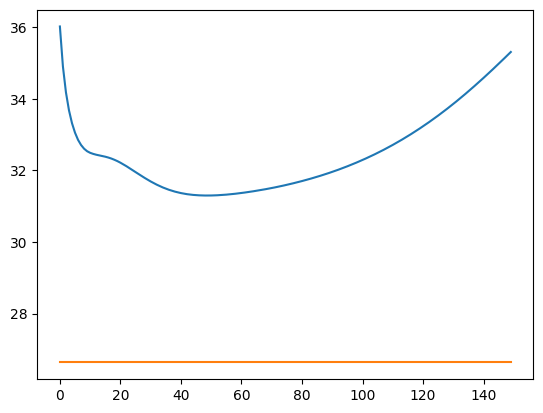

In [63]:
trivial_model_error= evaluate_model_on_dataset(evaluation_data_reduced,evaluation_target_reduced,trivial_model)
print("trivial error:",trivial_model_error)
plt.plot(error_list)
plt.plot(trivial_model_error*np.ones(len(error_list)))

So reducing the data size did not help. Let's try a different architecture, a forward neural network instead of an LSTM. I will do this in a separate notebook.